# Explainable ML for chronic kidney disease: a guided walkthrough

This notebook walks through the project **using the same code as the scripts and the app** (the `ckd_xai` package in `src/`). It does not re-run the full experiment; it loads the saved outputs of `python scripts/run_pipeline.py` and re-checks the key claims.

Sections: 1) data, 2) leak-free pipeline, 3) model selection, 4) final test, 5) reload and reproduce, 6) SHAP explanations, 7) limitations.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore', message='IProgress not found')   # harmless tqdm notice from shap
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np, pandas as pd
from IPython.display import Image, display
from ckd_xai import data, schema
from ckd_xai.config import load_config, TABLES_DIR, FIGURES_DIR, PROCESSED_DIR
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
cfg = load_config()
print('random seed:', cfg['project']['random_seed'])

random seed: 42


## 1. The data

The raw UCI file has stray tabs, `?` for missing values, two lines with a trailing comma and one with a doubled comma. `data.clean()` fixes each of these and logs every change. No record is removed.

In [2]:
df = data.load_clean()
summary = json.loads((PROCESSED_DIR / 'cleaning_summary.json').read_text())
print('records:', len(df), '| classes:', summary['class_counts'])
print('line repairs:', summary['line_repairs'])
print('impossible values set to missing:', [(d['feature'], d['value']) for d in summary['implausible_values_set_missing']])
print('cells that differ from UCI data.csv:', summary['cross_check']['n_cells_different'])
df.head()

records: 400 | classes: {'ckd': 250, 'notckd': 150}
line repairs: [{'record_id': 69, 'issue': 'trailing comma', 'action': 'dropped empty last field'}, {'record_id': 72, 'issue': 'trailing comma', 'action': 'dropped empty last field'}, {'record_id': 369, 'issue': 'doubled comma after field 19', 'action': 'dropped the empty field'}]
impossible values set to missing: [('sod', 4.5), ('pot', 39.0), ('pot', 47.0)]
cells that differ from UCI data.csv: 0


,record_id,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class,target
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,36.0,1.2,NaN,NaN,15.4,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd,1
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,18.0,0.8,NaN,NaN,11.3,38.0,6000.0,NaN,no,no,no,good,no,no,ckd,1
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,53.0,1.8,NaN,NaN,9.6,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd,1
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,56.0,3.8,111.0,2.5,11.2,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd,1
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,26.0,1.4,NaN,NaN,11.6,35.0,7300.0,4.6,no,no,no,good,no,no,ckd,1


In [3]:
pd.DataFrame(schema.feature_dictionary_rows())[['code', 'name', 'type', 'unit', 'values / limits']]

,code,name,type,unit,values / limits
0,age,Age,continuous,years,plausibility limits 0-120
1,bp,Blood pressure,continuous,mm Hg,plausibility limits 30-250
2,sg,Specific gravity,ordinal,-,"1.005, 1.01, 1.015, 1.02, 1.025"
3,al,Albumin grade,ordinal,-,"0, 1, 2, 3, 4, 5"
4,su,Sugar grade,ordinal,-,"0, 1, 2, 3, 4, 5"
5,rbc,Red blood cells,binary,-,normal (0) / abnormal (1)
6,pc,Pus cells,binary,-,normal (0) / abnormal (1)
7,pcc,Pus cell clumps,binary,-,notpresent (0) / present (1)
8,ba,Bacteria,binary,-,notpresent (0) / present (1)
9,bgr,Blood glucose (random),continuous,mg/dL,plausibility limits 10-1500


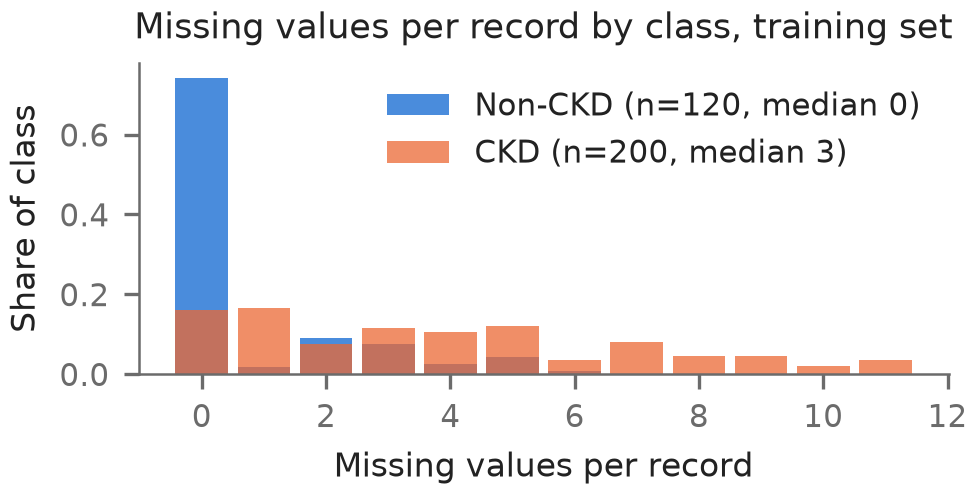

In [4]:
display(Image(filename=str(FIGURES_DIR / 'eda_missing_per_record_train.png'), width=420))

CKD records have many more missing values than non-CKD records. Keep this in mind: missingness itself carries class information (see section 3).

## 2. A leak-free pipeline

The test split is made once and locked. Every learned step (imputation, scaling, SMOTENC, classifier) lives inside one `imblearn` pipeline, so in cross-validation it is refitted on each training fold only. SMOTENC runs only during `fit`.

In [5]:
split = data.make_or_verify_split(df, cfg)
X_train, y_train = data.get_partition(df, split, 'train')
X_test, y_test = data.get_partition(df, split, 'test')
print('train', X_train.shape, y_train.value_counts().to_dict(), '| test', X_test.shape, y_test.value_counts().to_dict())

from ckd_xai.preprocessing import build_pipeline
pipe = build_pipeline('random_forest', cfg)
pipe

train (320, 24) {1: 200, 0: 120} | test (80, 24) {1: 50, 0: 30}


,steps,"[('prep', ...), ('resample', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('continuous', ...), ('ordinal', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"

In [6]:
# Show that SMOTENC adds synthetic non-CKD records during fit, but never at prediction time
pipe.fit(X_train, y_train)
prep, smote = pipe.named_steps['prep'], pipe.named_steps['resample']
X_res, y_res = smote.fit_resample(prep.transform(X_train), y_train)
print('training rows before / after SMOTENC:', len(X_train), '/', len(X_res), np.bincount(y_res))
print('prediction rows for the test set:', len(pipe.predict_proba(X_test)))

training rows before / after SMOTENC: 320 / 400 [200 200]
prediction rows for the test set: 80


## 3. Model selection used training-set cross-validation only

Rule fixed in `config.yaml` before the experiment: highest mean 5-fold CV ROC-AUC; models within 0.005 are tied and ranked by mean CV recall, then F1.

In [7]:
cv = pd.read_csv(TABLES_DIR / 'cv_model_comparison.csv')
cols = [f'{s}_{m}' for m in ['roc_auc', 'recall', 'f1'] for s in ('mean', 'std')]
display(cv[['display_name'] + cols].round(4))
sel = json.loads((ROOT / 'models' / 'selection.json').read_text())
print(sel['reason'])
print('test set used for selection:', sel['test_set_used'])

,display_name,mean_roc_auc,std_roc_auc,mean_recall,std_recall,mean_f1,std_f1
0,Logistic Regression,0.9994,0.0012,0.960,0.0406,0.9791,0.0213
1,SVM,1.0000,0.0000,0.985,0.0300,0.9922,0.0156
2,Random Forest,0.9994,0.0008,1.000,0.0000,0.9951,0.0060
3,XGBoost,0.9988,0.0017,0.985,0.0122,0.9851,0.0121


Models within 0.005 of the best mean CV ROC-AUC (1.0000) were treated as tied: Random Forest, SVM, XGBoost, Logistic Regression. Among them, Random Forest ranks first on the predeclared tie-breakers (mean CV recall, then f1, then simplicity).
test set used for selection: False


In [8]:
from ckd_xai.train import select_model
winner, ranking, _ = select_model(cv, cfg)   # re-apply the rule to the saved CV table
print('rule re-applied ->', winner)
display(pd.read_csv(TABLES_DIR / 'cv_resampling_ablation.csv')[['model', 'resampling', 'mean_roc_auc', 'mean_recall', 'mean_f1']].round(4))
display(pd.read_csv(TABLES_DIR / 'cv_missingness_probe.csv')[['probe', 'mean_roc_auc', 'std_roc_auc']].round(3))

rule re-applied -> random_forest


,model,resampling,mean_roc_auc,mean_recall,mean_f1
0,logistic_regression,SMOTENC,0.9994,0.960,0.9791
1,logistic_regression,none,0.9994,0.965,0.9818
2,svm,SMOTENC,1.0000,0.985,0.9922
3,svm,none,1.0000,0.995,0.9975
4,random_forest,SMOTENC,0.9994,1.000,0.9951
5,random_forest,none,0.9988,1.000,0.9927
6,xgboost,SMOTENC,0.9988,0.985,0.9851
7,xgboost,none,0.9990,0.990,0.9876


,probe,mean_roc_auc,std_roc_auc
0,missing-value indicators only (logistic regres...,0.864,0.047


SMOTENC gives no consistent improvement here, and a model that sees only *which* values are missing already reaches a high CV ROC-AUC.

## 4. Final evaluation on the untouched test set

In [9]:
tm = pd.read_csv(TABLES_DIR / 'test_metrics.csv')
display(tm[['display_name', 'roc_auc', 'accuracy', 'precision', 'recall', 'f1', 'fp', 'fn',
            'accuracy_exact_lo', 'accuracy_exact_hi']].round(4))
display(pd.read_csv(TABLES_DIR / 'leakage_audit.csv')[['check', 'passed']])

,display_name,roc_auc,accuracy,precision,recall,f1,fp,fn,accuracy_exact_lo,accuracy_exact_hi
0,Logistic Regression,1.0,0.975,1.0,0.96,0.9796,0,2,0.9126,0.997
1,SVM,1.0,1.000,1.0,1.00,1.0000,0,0,0.9549,1.000
2,Random Forest,1.0,1.000,1.0,1.00,1.0000,0,0,0.9549,1.000
3,XGBoost,1.0,1.000,1.0,1.00,1.0000,0,0,0.9549,1.000


,check,passed
0,Train and test record IDs are disjoint,True
1,No identical feature vector appears in both pa...,True
2,Test partition matches the split locked before...,True
3,Model chosen from training-set CV only (test u...,True
4,Imputation medians equal training-only medians,True
5,Scaling statistics equal training-only statistics,True
6,Predictors exclude ID and target,True
7,Resampling is not applied at prediction time,True
8,Resampler sits inside the fitted pipeline (fit...,True
9,Shuffled-label training falls to chance level,True


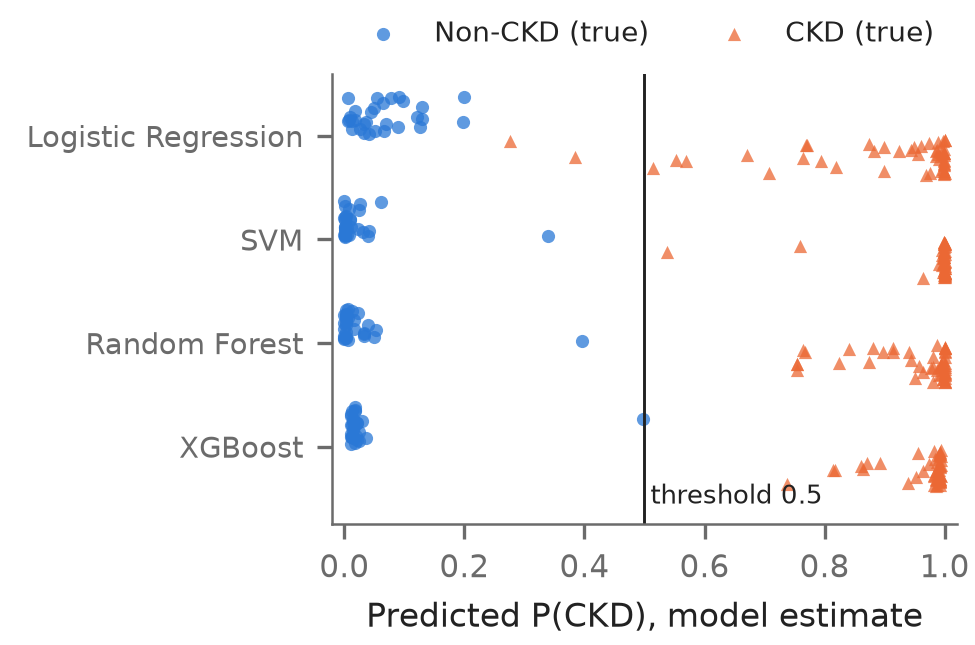

In [10]:
display(Image(filename=str(FIGURES_DIR / 'test_score_distributions.png'), width=480))

With only 80 test records, even 80/80 correct is compatible with a true accuracy as low as the exact 95% lower bound shown above.

## 5. Reload the saved model and reproduce its predictions

In [11]:
import joblib
from ckd_xai.config import SELECTED_MODEL_PATH
from ckd_xai.utils import ckd_probability
model = joblib.load(SELECTED_MODEL_PATH)
saved = pd.read_csv(TABLES_DIR / 'test_predictions.csv').set_index('record_id').loc[X_test.index]
p = ckd_probability(model, X_test)
print('max difference from saved predictions:', np.abs(p - saved[f"{sel['selected_model']}_p_ckd"]).max())

max difference from saved predictions: 3.33333333379926e-07


## 6. SHAP explanations

The explainer uses a background of 100 real training records. For the Random Forest the output explained is the **probability of CKD**, so the baseline plus the contributions must equal the predicted probability.

In [12]:
from ckd_xai.inference import CKDPredictor
predictor = CKDPredictor(cfg)
record = {k: (None if pd.isna(v) else v) for k, v in X_test.loc[26].items()}
res = predictor.predict(record)
ex = predictor.explain(res['record'])
print(f"P(CKD) = {res['p_ckd']:.3f} -> {res['class_name']} | imputed: {res['imputed_values']}")
print(f"baseline {ex['base_value']:.3f} + sum {ex['values'].sum():+.3f} = {ex['reconstructed_output']:.3f}; consistent: {ex['consistent']}")
ex['table'].head(8)

P(CKD) = 0.993 -> CKD | imputed: {'Red blood cells': 'normal'}
baseline 0.667 + sum +0.326 = 0.993; consistent: True


,feature,label,value,imputed,shap
0,sc,Serum creatinine,2.4 mg/dL,False,0.067429
1,sg,Specific gravity,1.015,False,0.057722
2,hemo,Haemoglobin,11.6 g/dL,False,0.049117
3,htn,Hypertension,yes,False,0.039011
4,dm,Diabetes mellitus,yes,False,0.036074
5,pcv,Packed cell volume,35,False,0.032829
6,bgr,Blood glucose (random),156 mg/dL,False,0.025690
7,rbcc,Red blood cell count,4 millions/cmm,False,0.018770


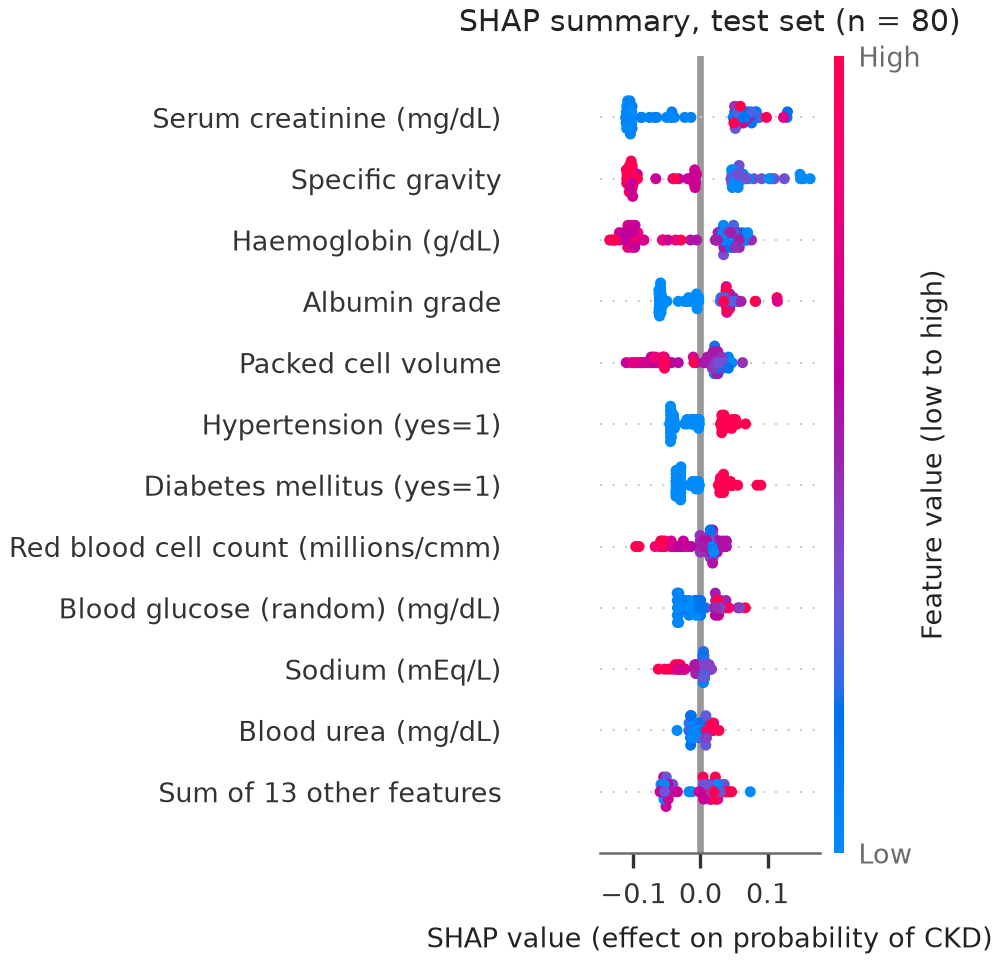

In [13]:
display(Image(filename=str(FIGURES_DIR / 'shap_beeswarm.png'), width=460))

In [14]:
imp = pd.read_csv(TABLES_DIR / 'shap_global_importance.csv')
imp[['label', 'mean_abs_shap_test', 'rank_test', 'rank_train']].head(10).round(4)

,label,mean_abs_shap_test,rank_test,rank_train
0,Serum creatinine,0.0791,1,1
1,Specific gravity,0.0745,2,3
2,Haemoglobin,0.0667,3,2
3,Albumin grade,0.0447,4,4
4,Packed cell volume,0.0427,5,5
5,Hypertension,0.0331,6,6
6,Diabetes mellitus,0.0306,7,8
7,Red blood cell count,0.0263,8,7
8,Blood glucose (random),0.0221,9,9
9,Sodium,0.0122,10,11


## 7. Limitations to remember

* 400 records from one hospital; 80 test records.
* Classes are very easy to separate in this dataset; it says little about early or borderline CKD.
* Missingness is informative, so part of the signal may reflect which tests were ordered.
* Probabilities come from a model trained on balanced data and are not calibrated risks.
* SHAP explains the model's behaviour, not clinical causation.
* No external validation has been done; this is an educational prototype, not a diagnostic tool.